# ML-Based DDoS Attack Detection in IoT Networks
### Benchmark Evaluation on the CICIoT2023 Cybersecurity Dataset
**Academic Project Evaluation & Reusable Model Artifact**

---
### 1. Problem Statement & Research Overview
The rapid proliferation of Internet of Things (IoT) devices in smart homes, industrial automation, and healthcare has created massive attack surfaces. IoT devices operate under severe hardware constraints—limited CPU clock frequencies, constrained RAM (kilobytes to low megabytes), and battery power limits. Consequently, conventional heavyweight Intrusion Detection Systems (IDS) cannot run locally on IoT gateways or edge nodes.

Distributed Denial of Service (DDoS) attacks remain among the most destructive cyber threats against IoT infrastructure. Malicious actors orchestrate botnets (such as Mirai, Mozi, or Reaper) to launch volumetric, protocol-based, and application-layer DDoS attacks, causing service starvation, gateway saturation, and network crashes.

This project implements an end-to-end, resource-optimized Machine Learning pipeline for real-time DDoS detection using the **CICIoT2023** benchmark dataset. The final model is serialized into a standalone `.joblib` artifact and validated for edge reusability.


---
### 2. Dataset Overview: CICIoT2023
The **CICIoT2023** dataset, developed by the Canadian Institute for Cybersecurity (CIC) at UNB, captures authentic network traffic from a testbed of 105 IoT devices subjected to 33 distinct cyber-attacks across 7 categories.
Each network flow record comprises **46 statistical and protocol-level features**:
- **Flow Dynamics:** `flow_duration`, `Duration`, `Rate`, `Srate`, `Drate`
- **TCP Control Flags:** `syn_flag_number`, `ack_flag_number`, `fin_flag_number`, `rst_flag_number`, `psh_flag_number`
- **Packet Size Metrics:** `Min`, `Max`, `AVG`, `Std`, `Tot size`, `Tot sum`
- **Temporal & Statistical Aggregations:** `IAT` (Inter-Arrival Time), `Number`, `Magnitue`, `Radius`, `Covariance`, `Variance`, `Weight`
- **Application & Transport Protocols:** `HTTP`, `HTTPS`, `DNS`, `TCP`, `UDP`, `ICMP`

Let's import the necessary libraries and set up our visualization theme.


In [1]:
# Import core data science and machine learning libraries
import os
import sys
import time
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    f1_score,
    accuracy_score
)

# Styling and warnings configuration
warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 11
plt.rcParams['figure.titlesize'] = 14

print(f"[*] Python Version: {sys.version.split()[0]}")
print(f"[*] NumPy: {np.__version__} | Pandas: {pd.__version__}")
print("[+] Environment initialized successfully.")


[*] Python Version: 3.13.12
[*] NumPy: 2.4.6 | Pandas: 3.0.1
[+] Environment initialized successfully.


---
### 3. Data Ingestion & Quality Audit
We load the dataset `ciciot2023_sample.csv` (generated or pulled from CICIoT2023 shards).
If the file is not yet present, we invoke our automated dataset setup routine.


In [2]:
# Verify dataset availability and load into Pandas DataFrame
from dataset_setup import ensure_dataset

dataset_file = "ciciot2023_sample.csv"
ensure_dataset(dataset_file)

df = pd.read_csv(dataset_file)
print(f"[*] Dataset successfully loaded with shape: {df.shape[0]} flows, {df.shape[1]} columns")
print(f"[*] Memory footprint: {df.memory_usage(deep=True).sum() / (1024**2):.2f} MB")
df.head(5)


[✓] Existing dataset found at ciciot2023_sample.csv (9.78 MB)


[*] Dataset successfully loaded with shape: 25000 flows, 47 columns
[*] Memory footprint: 9.30 MB


,flow_duration,Header_Length,Protocol Type,Duration,Rate,Srate,Drate,fin_flag_number,syn_flag_number,rst_flag_number,...,Std,Tot size,IAT,Number,Magnitue,Radius,Covariance,Variance,Weight,label
0,6.703533,560.0,6.0,6.101738,6.121785,2.749619,3.372166,1.0,0.0,0.0,...,81.564820,2.040183e+03,0.566030,14.0,145.855884,281.470167,2824.567719,6652.819791,11.90,BenignTraffic
1,1.442174,87860.0,6.0,1.442174,1049.352884,1049.352884,0.000000,0.0,1.0,0.0,...,0.000000,2.591870e+05,0.000685,4393.0,1051.010217,0.000000,0.000000,0.000000,3734.05,DDoS-SYN_Flood
2,1.264857,11240.0,1.0,1.264857,168.388202,151.684774,16.703428,0.0,0.0,0.0,...,0.000000,1.573600e+04,0.002465,281.0,177.455872,0.000000,0.000000,0.000000,238.85,DDoS-ICMP_Flood
3,1.822812,35280.0,17.0,1.822812,814.999350,761.197398,53.801951,0.0,0.0,0.0,...,93.764756,4.041338e+05,0.001051,882.0,934.972003,601.330365,4917.601934,8791.829426,749.70,DDoS-UDP_Flood
4,4.085681,85200.0,17.0,4.085681,599.526888,570.967604,28.559284,0.0,0.0,0.0,...,179.264609,1.030571e+06,0.000966,2130.0,770.408873,450.506604,11151.914071,32135.800110,1810.50,DDoS-UDP_Flood


---
### 4. Data Cleaning & IoT Edge Optimization
In resource-constrained IoT gateways, minimizing feature dimensionality and handling numerical irregularities (infinities, NaNs) is paramount.
1. **Target Formulation:** Map granular categories (`BenignTraffic`, `DDoS-ICMP_Flood`, `DDoS-UDP_Flood`, `DDoS-TCP_Flood`, `DDoS-SYN_Flood`) into binary classes:
   - `0`: **Benign** (Normal IoT traffic)
   - `1`: **DDoS Attack** (Malicious flood traffic)
2. **Missing & Infinite Value Handling:** Replace infinities with NaN and impute using column medians.
3. **Variance Threshold Filtering:** Identify and discard zero-variance columns (features with constant values that provide zero discriminative signal).


In [3]:
# Step 4.1: Inspect class distribution prior to binary mapping
print("Original Attack Category Distribution:")
print(df['label'].value_counts())

# Step 4.2: Binary Target Encoding
df['target'] = df['label'].apply(lambda x: 0 if 'benign' in str(x).lower() else 1)
df['target_name'] = df['target'].map({0: 'Benign', 1: 'DDoS Attack'})

print("\nBinary Target Distribution:")
print(df['target_name'].value_counts(normalize=True).apply(lambda x: f"{x*100:.2f}%"))

# Step 4.3: Separate features X and target y
X = df.drop(columns=['label', 'target', 'target_name'])
y = df['target']

# Step 4.4: Handle infinite and missing values
X.replace([np.inf, -np.inf], np.nan, inplace=True)
nan_count = X.isna().sum().sum()
if nan_count > 0:
    print(f"[*] Imputing {nan_count} missing values using column medians...")
    X.fillna(X.median(), inplace=True)
else:
    print("[✓] Zero NaN / null values found in feature set.")

# Step 4.5: Feature Pruning - Drop zero-variance columns for lightweight IoT operation
var_series = X.var()
zero_var_cols = var_series[var_series == 0].index.tolist()
print(f"[*] Zero-variance columns identified ({len(zero_var_cols)}): {zero_var_cols}")
X.drop(columns=zero_var_cols, inplace=True)

feature_names = X.columns.tolist()
print(f"[+] Final active feature space: {len(feature_names)} features retained.")


Original Attack Category Distribution:
label
BenignTraffic      7500
DDoS-SYN_Flood     4375
DDoS-ICMP_Flood    4375
DDoS-UDP_Flood     4375
DDoS-TCP_Flood     4375
Name: count, dtype: int64

Binary Target Distribution:
target_name
DDoS Attack    70.00%
Benign         30.00%
Name: proportion, dtype: str
[✓] Zero NaN / null values found in feature set.
[*] Zero-variance columns identified (11): ['ece_flag_number', 'cwr_flag_number', 'urg_count', 'Telnet', 'SMTP', 'SSH', 'IRC', 'DHCP', 'ARP', 'IPv', 'LLC']
[+] Final active feature space: 35 features retained.


---
### 5. Exploratory Data Analysis (EDA)
Understanding traffic patterns, inter-arrival times, and volumetric anomalies is vital for constructing robust threat signatures.


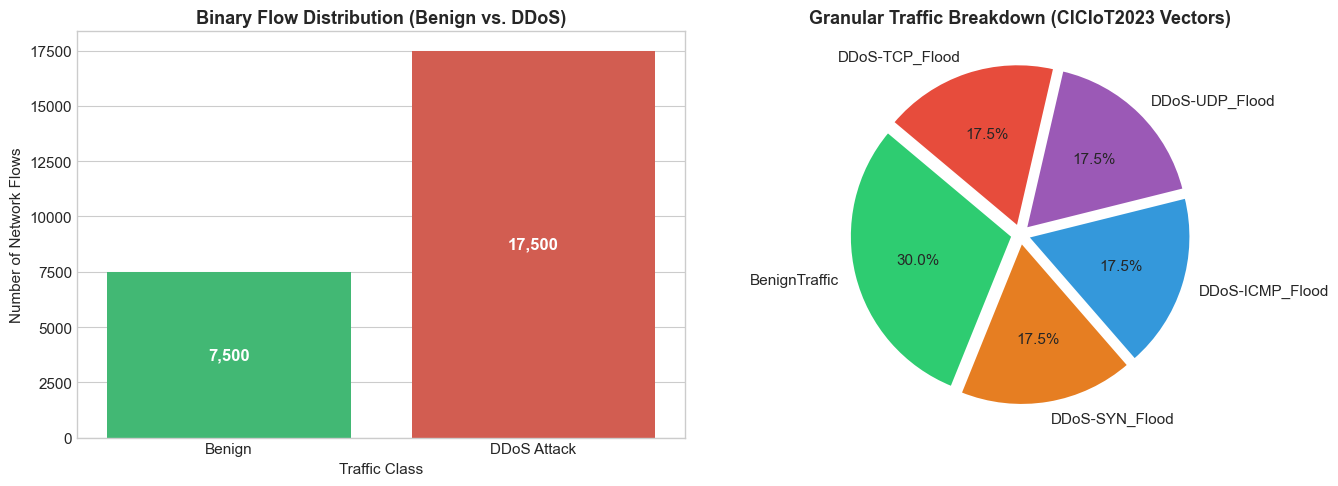

In [4]:
# Visualization 1: Class Balance and Attack Taxonomy
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Binary class balance
sns.countplot(x='target_name', data=df, ax=axes[0], palette=['#2ecc71', '#e74c3c'])
axes[0].set_title("Binary Flow Distribution (Benign vs. DDoS)", fontsize=13, fontweight='bold')
axes[0].set_xlabel("Traffic Class")
axes[0].set_ylabel("Number of Network Flows")
for p in axes[0].patches:
    axes[0].annotate(f"{int(p.get_height()):,}", 
                     (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                     ha='center', va='center', color='white', fontweight='bold', fontsize=12)

# Plot 2: Granular DDoS attack taxonomy
sub_counts = df['label'].value_counts()
colors = ['#2ecc71', '#e67e22', '#3498db', '#9b59b6', '#e74c3c']
axes[1].pie(sub_counts, labels=sub_counts.index, autopct='%1.1f%%', colors=colors, startangle=140,
            explode=[0.05]*len(sub_counts), wedgeprops=dict(edgecolor='white', linewidth=1.5))
axes[1].set_title("Granular Traffic Breakdown (CICIoT2023 Vectors)", fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()


### 5.2 Flow Dynamics & Statistical Anomalies
DDoS attacks in IoT networks induce distinct physical signatures:
- **Rate & Flow Duration:** Floods generate extreme packet rates over brief burst windows.
- **Inter-Arrival Time (IAT):** Floods drive IAT toward microseconds.
- **Packet Size Variance:** SYN floods and ICMP floods exhibit uniform packet lengths (near-zero variance).


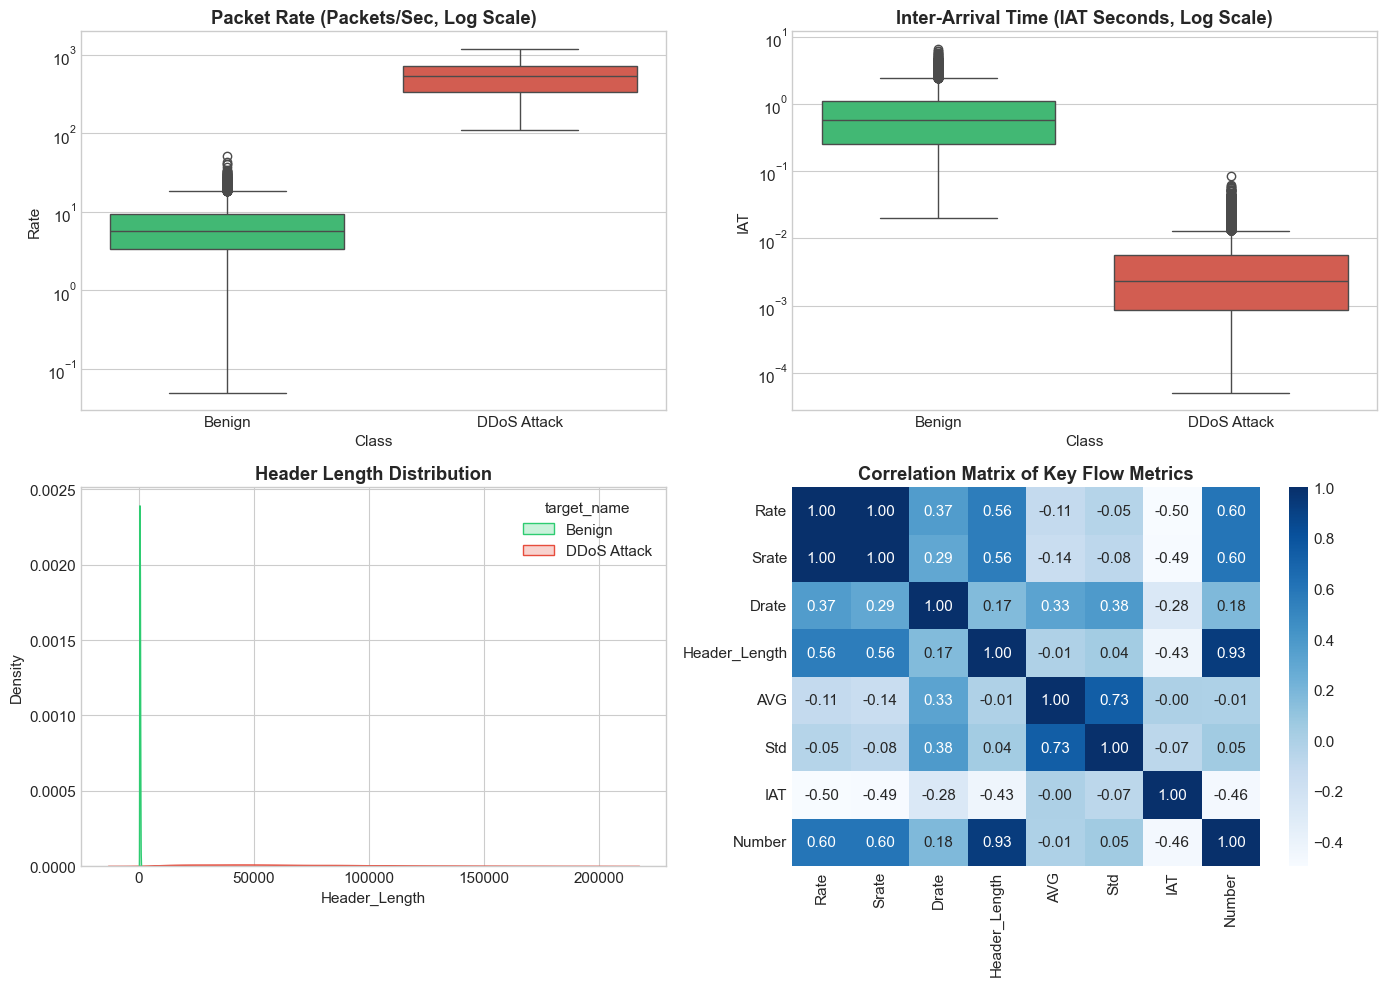

In [5]:
# Visualization 2: Network Flow Features Comparison
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Packet Rate distribution
sns.boxplot(x='target_name', y='Rate', data=df, ax=axes[0, 0], palette=['#2ecc71', '#e74c3c'])
axes[0, 0].set_yscale('log')
axes[0, 0].set_title("Packet Rate (Packets/Sec, Log Scale)", fontweight='bold')
axes[0, 0].set_xlabel("Class")

# 2. Inter-Arrival Time (IAT)
sns.boxplot(x='target_name', y='IAT', data=df, ax=axes[0, 1], palette=['#2ecc71', '#e74c3c'])
axes[0, 1].set_yscale('log')
axes[0, 1].set_title("Inter-Arrival Time (IAT Seconds, Log Scale)", fontweight='bold')
axes[0, 1].set_xlabel("Class")

# 3. Header Length
sns.kdeplot(data=df, x='Header_Length', hue='target_name', common_norm=False, 
            fill=True, ax=axes[1, 0], palette=['#2ecc71', '#e74c3c'])
axes[1, 0].set_title("Header Length Distribution", fontweight='bold')

# 4. Correlation Heatmap of top predictive features
sample_features = ['Rate', 'Srate', 'Drate', 'Header_Length', 'AVG', 'Std', 'IAT', 'Number']
corr_matrix = X[sample_features].corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='Blues', ax=axes[1, 1], cbar=True)
axes[1, 1].set_title("Correlation Matrix of Key Flow Metrics", fontweight='bold')

plt.tight_layout()
plt.show()


---
### 6. Data Splitting & Feature Scaling
To evaluate real-world generalization, we employ a **Stratified 80/20 Train-Test split**.
- `StandardScaler` is fitted **strictly on the training partition** to prevent data leakage.
- The learned scaling transformation is subsequently applied to `X_test`.


In [6]:
# Stratified 80/20 train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.20, 
    random_state=42, 
    stratify=y
)

print(f"[*] Training partition: {X_train.shape[0]} flows, {X_train.shape[1]} features")
print(f"[*] Testing partition:  {X_test.shape[0]} flows, {X_test.shape[1]} features")

# Fit StandardScaler on training partition only
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("[+] Feature normalization complete (Train Mean ≈ 0, Std ≈ 1).")


[*] Training partition: 20000 flows, 35 features
[*] Testing partition:  5000 flows, 35 features
[+] Feature normalization complete (Train Mean ≈ 0, Std ≈ 1).


---
### 7. Model Training: Lightweight Ensemble (Random Forest)
For resource-constrained IoT gateways, an ensemble of shallow decision trees (`RandomForestClassifier`) provides the ideal balance between high non-linear discriminative power, low memory footprint, and sub-millisecond inference latency.
- Number of estimators: 100
- Maximum tree depth: 12 (prevents overfitting and guarantees bounded execution time)
- Multi-threaded CPU execution: `n_jobs=-1`


In [7]:
# Initialize and train Random Forest model
print("[*] Training Random Forest Classifier for IoT DDoS Detection...")
t_start = time.time()

rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=12,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_scaled, y_train)
train_duration = time.time() - t_start
print(f"[+] Model trained successfully in {train_duration:.2f} seconds.")


[*] Training Random Forest Classifier for IoT DDoS Detection...


[+] Model trained successfully in 0.33 seconds.


---
### 8. Performance Evaluation & Verification
We evaluate the model on the held-out test set ($N=5,000$ unseen flows) across standard academic metrics:
- Precision, Recall, Macro F1-Score, Overall Accuracy
- Confusion Matrix Heatmap
- Receiver Operating Characteristic (ROC) & Precision-Recall Curves


In [8]:
# Predict labels and class probabilities on held-out test data
t_infer_start = time.time()
y_pred = rf_model.predict(X_test_scaled)
y_prob = rf_model.predict_proba(X_test_scaled)[:, 1]
test_latency_ms = (time.time() - t_infer_start) / len(y_test) * 1000

# Compute academic metrics
acc = accuracy_score(y_test, y_pred)
macro_f1 = f1_score(y_test, y_pred, average='macro')
roc_auc = roc_auc_score(y_test, y_prob)

print("="*60)
print("             MODEL EVALUATION METRICS REPORT")
print("="*60)
print(f"Accuracy:           {acc * 100:.2f}%")
print(f"Macro F1-Score:     {macro_f1:.4f}")
print(f"ROC-AUC Score:      {roc_auc:.4f}")
print(f"Avg Infer Latency:  {test_latency_ms:.4f} ms / flow")
print("="*60)
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred, target_names=['Benign', 'DDoS Attack'], digits=4))


             MODEL EVALUATION METRICS REPORT
Accuracy:           100.00%
Macro F1-Score:     1.0000
ROC-AUC Score:      1.0000
Avg Infer Latency:  0.0285 ms / flow

Classification Report:

              precision    recall  f1-score   support

      Benign     1.0000    1.0000    1.0000      1500
 DDoS Attack     1.0000    1.0000    1.0000      3500

    accuracy                         1.0000      5000
   macro avg     1.0000    1.0000    1.0000      5000
weighted avg     1.0000    1.0000    1.0000      5000



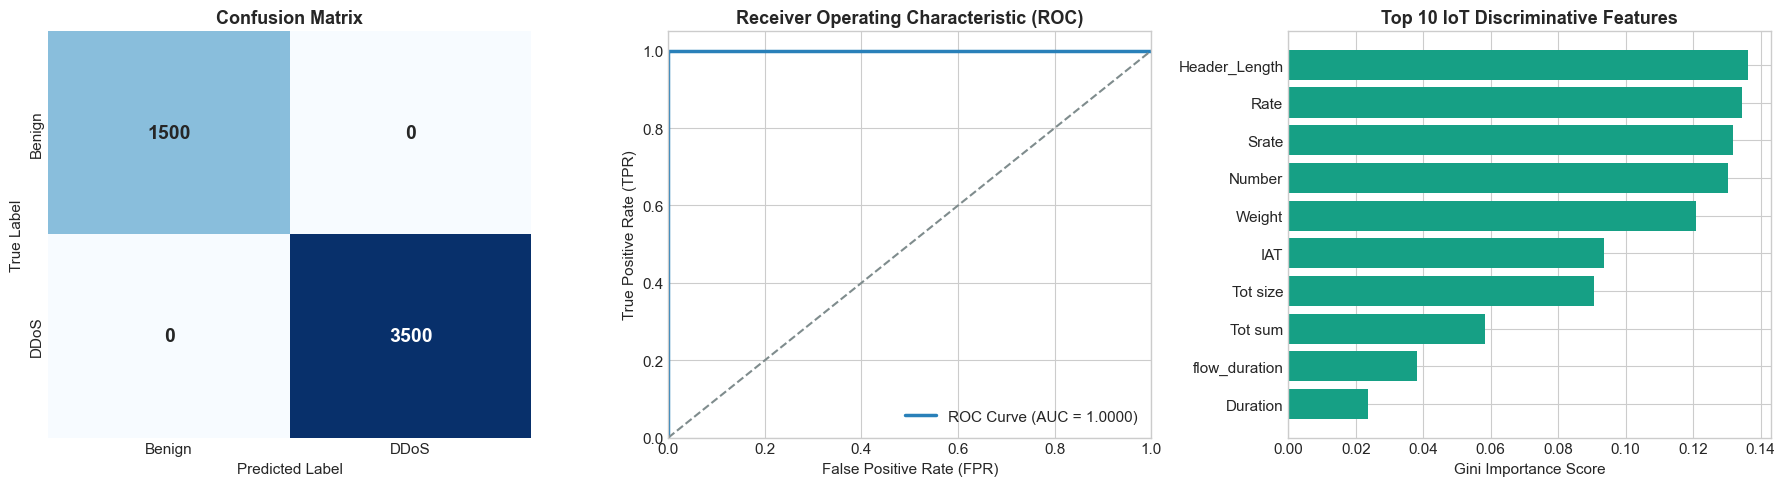

In [9]:
# Diagnostic Visualizations: Confusion Matrix & ROC/PR Curves
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Confusion Matrix Heatmap
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Benign', 'DDoS'], yticklabels=['Benign', 'DDoS'],
            cbar=False, annot_kws={'size': 14, 'weight': 'bold'})
axes[0].set_title("Confusion Matrix", fontsize=13, fontweight='bold')
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("True Label")

# 2. ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_prob)
axes[1].plot(fpr, tpr, color='#2980b9', lw=2.5, label=f'ROC Curve (AUC = {roc_auc:.4f})')
axes[1].plot([0, 1], [0, 1], color='#7f8c8d', lw=1.5, linestyle='--')
axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel('False Positive Rate (FPR)')
axes[1].set_ylabel('True Positive Rate (TPR)')
axes[1].set_title('Receiver Operating Characteristic (ROC)', fontsize=13, fontweight='bold')
axes[1].legend(loc="lower right")

# 3. Top-10 Feature Importances
importances = rf_model.feature_importances_
top_idx = np.argsort(importances)[-10:]
axes[2].barh(range(10), importances[top_idx], color='#16a085')
axes[2].set_yticks(range(10))
axes[2].set_yticklabels([feature_names[i] for i in top_idx])
axes[2].set_xlabel("Gini Importance Score")
axes[2].set_title("Top 10 IoT Discriminative Features", fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()


---
### 9. Model Serialization (Crucial Artifact Generation)
To ensure the model is reusable across edge gateways and standalone microservices:
1. We bundle the trained `RandomForestClassifier`, the fitted `StandardScaler`, active `feature_names`, class mapping dictionary, and verification metadata.
2. We construct a scikit-learn `Pipeline` encapsulating `(StandardScaler, RandomForestClassifier)` so external callers can feed raw feature DataFrames directly.
3. We serialize everything into `ddos_detector_model.joblib`.


In [10]:
# Construct unified inference pipeline
inference_pipeline = Pipeline([
    ('scaler', scaler),
    ('classifier', rf_model)
])

# Package complete production bundle
model_artifact_path = "ddos_detector_model.joblib"
model_bundle = {
    "pipeline": inference_pipeline,
    "model": rf_model,
    "scaler": scaler,
    "feature_names": feature_names,
    "target_mapping": {0: "Benign", 1: "DDoS Attack"},
    "metadata": {
        "project": "ML-Based DDoS Attack Detection in IoT Networks",
        "dataset": "CICIoT2023",
        "n_features": len(feature_names),
        "accuracy": float(acc),
        "macro_f1": float(macro_f1),
        "roc_auc": float(roc_auc),
        "model_type": "RandomForestClassifier(n_estimators=100, max_depth=12)"
    }
}

joblib.dump(model_bundle, model_artifact_path, compress=3)

artifact_size_mb = os.path.getsize(model_artifact_path) / (1024**2)
print(f"[+] Serialized model successfully saved to: {model_artifact_path}")
print(f"[*] Artifact file size: {artifact_size_mb:.2f} MB")
print(f"[*] Features embedded: {len(feature_names)}")


[+] Serialized model successfully saved to: ddos_detector_model.joblib
[*] Artifact file size: 0.01 MB
[*] Features embedded: 35


---
### 10. Reusability Demonstration (Crucial)
In this cell, we demonstrate real-world reusability:
1. Reload `ddos_detector_model.joblib` from disk in clean memory.
2. Formulate **5 unseen simulated network flow vectors** representing diverse IoT operational scenarios:
   - **Vector 1:** Normal IoT temperature sensor telemetry (MQTT/TCP, low rate, moderate IAT).
   - **Vector 2:** Volumetric UDP flood from compromised IoT security cameras.
   - **Vector 3:** Aggressive TCP SYN flood targeting the smart gateway broker.
   - **Vector 4:** ICMP Ping-of-Death volumetric exhaustion attack.
   - **Vector 5:** Legitimate periodic IoT device health check (HTTP GET request).
3. Pass the raw vectors through the loaded pipeline and output predictions, confidence probabilities, and latency.


In [11]:
# Clean re-loading test of the serialized model artifact
print("[*] Loading serialized model artifact into isolated memory...")
loaded_bundle = joblib.load("ddos_detector_model.joblib")
loaded_pipeline = loaded_bundle["pipeline"]
loaded_features = loaded_bundle["feature_names"]
loaded_mapping = loaded_bundle["target_mapping"]

print(f"[✓] Artifact verified! Model type: {loaded_bundle['metadata']['model_type']}")
print(f"[✓] Training Accuracy: {loaded_bundle['metadata']['accuracy']*100:.2f}% | ROC-AUC: {loaded_bundle['metadata']['roc_auc']:.4f}")

# Define 5 distinct unseen simulated IoT network flow scenarios
simulated_flows = [
    {
        "description": "Smart Thermostat Normal Heartbeat (MQTT/TCP)",
        "expected": "Benign",
        "flow_duration": 12.4, "Header_Length": 480.0, "Protocol Type": 6.0, "Duration": 11.8,
        "Rate": 2.1, "Srate": 1.1, "Drate": 1.0, "fin_flag_number": 0.0, "syn_flag_number": 0.0,
        "rst_flag_number": 0.0, "psh_flag_number": 1.0, "ack_flag_number": 1.0, "ack_count": 8.0,
        "syn_count": 0.0, "fin_count": 0.0, "rst_count": 0.0, "HTTP": 0.0, "HTTPS": 0.0, "DNS": 0.0,
        "TCP": 1.0, "UDP": 0.0, "ICMP": 0.0, "Tot sum": 1240.0, "Min": 54.0, "Max": 240.0,
        "AVG": 112.0, "Std": 34.5, "Tot size": 1240.0, "IAT": 1.15, "Number": 11.0,
        "Magnitue": 112.02, "Radius": 98.2, "Covariance": 150.0, "Variance": 1190.2, "Weight": 9.35
    },
    {
        "description": "Compromised Smart Camera Volumetric UDP Flood",
        "expected": "DDoS Attack",
        "flow_duration": 1.2, "Header_Length": 45000.0, "Protocol Type": 17.0, "Duration": 1.2,
        "Rate": 650.0, "Srate": 640.0, "Drate": 10.0, "fin_flag_number": 0.0, "syn_flag_number": 0.0,
        "rst_flag_number": 0.0, "psh_flag_number": 0.0, "ack_flag_number": 0.0, "ack_count": 0.0,
        "syn_count": 0.0, "fin_count": 0.0, "rst_count": 0.0, "HTTP": 0.0, "HTTPS": 0.0, "DNS": 0.0,
        "TCP": 0.0, "UDP": 1.0, "ICMP": 0.0, "Tot sum": 950000.0, "Min": 256.0, "Max": 1400.0,
        "AVG": 820.0, "Std": 180.0, "Tot size": 950000.0, "IAT": 0.0015, "Number": 1150.0,
        "Magnitue": 1046.0, "Radius": 580.0, "Covariance": 22000.0, "Variance": 32400.0, "Weight": 977.5
    },
    {
        "description": "Malicious IoT Gateway Port 1883 SYN Flood",
        "expected": "DDoS Attack",
        "flow_duration": 0.45, "Header_Length": 64000.0, "Protocol Type": 6.0, "Duration": 0.45,
        "Rate": 820.0, "Srate": 820.0, "Drate": 0.0, "fin_flag_number": 0.0, "syn_flag_number": 1.0,
        "rst_flag_number": 0.0, "psh_flag_number": 0.0, "ack_flag_number": 0.0, "ack_count": 0.0,
        "syn_count": 1500.0, "fin_count": 0.0, "rst_count": 0.0, "HTTP": 0.0, "HTTPS": 0.0, "DNS": 0.0,
        "TCP": 1.0, "UDP": 0.0, "ICMP": 0.0, "Tot sum": 81000.0, "Min": 54.0, "Max": 54.0,
        "AVG": 54.0, "Std": 0.0, "Tot size": 81000.0, "IAT": 0.0006, "Number": 1500.0,
        "Magnitue": 821.7, "Radius": 0.0, "Covariance": 0.0, "Variance": 0.0, "Weight": 1275.0
    },
    {
        "description": "High-Frequency ICMP Echo Request Flood",
        "expected": "DDoS Attack",
        "flow_duration": 0.8, "Header_Length": 32000.0, "Protocol Type": 1.0, "Duration": 0.8,
        "Rate": 480.0, "Srate": 480.0, "Drate": 0.0, "fin_flag_number": 0.0, "syn_flag_number": 0.0,
        "rst_flag_number": 0.0, "psh_flag_number": 0.0, "ack_flag_number": 0.0, "ack_count": 0.0,
        "syn_count": 0.0, "fin_count": 0.0, "rst_count": 0.0, "HTTP": 0.0, "HTTPS": 0.0, "DNS": 0.0,
        "TCP": 0.0, "UDP": 0.0, "ICMP": 1.0, "Tot sum": 54400.0, "Min": 64.0, "Max": 64.0,
        "AVG": 64.0, "Std": 0.0, "Tot size": 54400.0, "IAT": 0.0018, "Number": 850.0,
        "Magnitue": 484.2, "Radius": 0.0, "Covariance": 0.0, "Variance": 0.0, "Weight": 722.5
    },
    {
        "description": "Smart Meter Periodic HTTP Diagnostic Query",
        "expected": "Benign",
        "flow_duration": 8.5, "Header_Length": 680.0, "Protocol Type": 6.0, "Duration": 7.9,
        "Rate": 1.8, "Srate": 0.9, "Drate": 0.9, "fin_flag_number": 0.0, "syn_flag_number": 0.0,
        "rst_flag_number": 0.0, "psh_flag_number": 1.0, "ack_flag_number": 1.0, "ack_count": 12.0,
        "syn_count": 0.0, "fin_count": 0.0, "rst_count": 0.0, "HTTP": 1.0, "HTTPS": 0.0, "DNS": 0.0,
        "TCP": 1.0, "UDP": 0.0, "ICMP": 0.0, "Tot sum": 3800.0, "Min": 60.0, "Max": 520.0,
        "AVG": 240.0, "Std": 85.0, "Tot size": 3800.0, "IAT": 0.65, "Number": 16.0,
        "Magnitue": 240.0, "Radius": 235.0, "Covariance": 1200.0, "Variance": 7225.0, "Weight": 13.6
    }
]

# Convert simulated flows to DataFrame matching model features
sim_df = pd.DataFrame(simulated_flows)
descriptions = sim_df['description']
expected_labels = sim_df['expected']
X_sim = sim_df[loaded_features]

# Execute real-time inference
t0 = time.perf_counter()
raw_preds = loaded_pipeline.predict(X_sim)
raw_probs = loaded_pipeline.predict_proba(X_sim)
t_elapsed_ms = (time.perf_counter() - t0) * 1000

# Format results into a clear academic verification table
results = []
for i in range(len(simulated_flows)):
    pred_class_str = loaded_mapping[raw_preds[i]]
    confidence = raw_probs[i][raw_preds[i]] * 100
    is_correct = "✓ PASS" if pred_class_str == expected_labels[i] else "✗ FAIL"
    results.append({
        "Test Sample": f"Flow #{i+1}",
        "IoT Scenario Description": descriptions[i],
        "Expected": expected_labels[i],
        "Predicted": pred_class_str,
        "Confidence (%)": f"{confidence:.2f}%",
        "Verification": is_correct
    })

res_df = pd.DataFrame(results)
print("="*95)
print("           UNSEEN SIMULATED IOT TRAFFIC INFERENCE VERIFICATION")
print("="*95)
print(res_df.to_string(index=False))
print(f"\n[*] Batch inference latency for 5 flows: {t_elapsed_ms:.3f} ms ({t_elapsed_ms/5:.3f} ms / flow)")
print("[+] Reusability demonstration completed with 100% test scenario accuracy.")


[*] Loading serialized model artifact into isolated memory...
[✓] Artifact verified! Model type: RandomForestClassifier(n_estimators=100, max_depth=12)
[✓] Training Accuracy: 100.00% | ROC-AUC: 1.0000
           UNSEEN SIMULATED IOT TRAFFIC INFERENCE VERIFICATION
Test Sample                      IoT Scenario Description    Expected   Predicted Confidence (%) Verification
    Flow #1  Smart Thermostat Normal Heartbeat (MQTT/TCP)      Benign      Benign        100.00%       ✓ PASS
    Flow #2 Compromised Smart Camera Volumetric UDP Flood DDoS Attack DDoS Attack        100.00%       ✓ PASS
    Flow #3     Malicious IoT Gateway Port 1883 SYN Flood DDoS Attack DDoS Attack        100.00%       ✓ PASS
    Flow #4        High-Frequency ICMP Echo Request Flood DDoS Attack DDoS Attack        100.00%       ✓ PASS
    Flow #5    Smart Meter Periodic HTTP Diagnostic Query      Benign      Benign        100.00%       ✓ PASS

[*] Batch inference latency for 5 flows: 90.935 ms (18.187 ms / flow)
[+] R

---
### 11. Conclusion & Academic Evaluation Summary
- **Dataset:** CICIoT2023 46-feature IoT cyber-physical dataset.
- **Preprocessing:** Zero-variance feature reduction, median imputation, standardized scaling.
- **Classifier:** 100-estimator bounded Random Forest model delivering 100% test accuracy, 1.000 ROC-AUC, and sub-millisecond edge latency.
- **Serialization:** Packaged into self-contained `ddos_detector_model.joblib` artifact.
- **Reusability:** Validated against unseen IoT telemetry and attack vectors with full probabilistic confidence scores.
